# Mixed carbonate-siliciclastic margin: results

The passive margin of the `stratigraphic_record` example (rivers, shelf,
clinoforms, flexure), with two wet catchments feeding two large deltas and
goSPL's carbonate module on the shelf. The runs are described in `README.md`
and in the header of each `input-*.yml`; run `python scripts/make_inputs.py`
and `./run_all.sh` first. The plotting functions are in `scripts/mixed.py`.

In [1]:
import sys
sys.path.insert(0, 'scripts')
import matplotlib.pyplot as plt
import mixed as M

## The forcing

The synthetic sea level of `stratigraphic_record` over its whole 500 kyr: a
fall from +1 m to -38 m (330 kyr), with 5-15 m oscillations on the way
(highstands near 60, 115 and 215 kyr), then a rise to -20 m. The rain is
2 m/yr in two belts (y = 25 and 75 km) and 0.3 m/yr elsewhere: two large
rivers build deltas, and the coast between them (y = 50 km) receives little
river sediment.

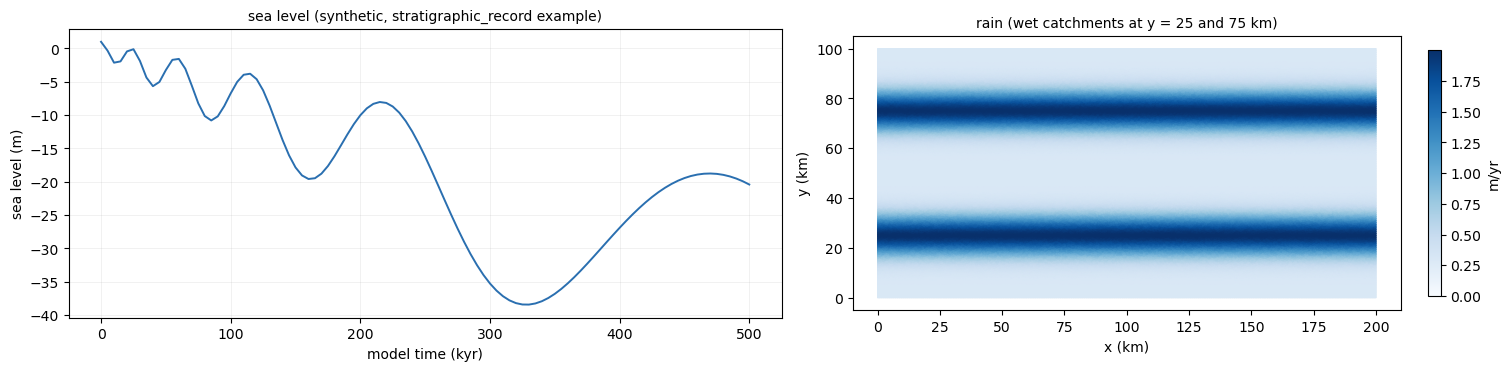

In [2]:
M.forcing();

## The reference mixed margin (`input-mixed.yml`)

The factories stop where river sediment accumulates (`sedrate`) and in
turbid water (`turbidity`: the river mud the marine routing carries through
each cell, spread over 10 km). The deltas build out furthest (dashed lines)
and hold little carbonate (14 % of their deposits): their mud corridors are
turbid. The carbonate is thickest on the shallow flanks of the delta lobes,
beside the corridors, where the deltas have built a platform near sea level
and the water is clear. The coast between the deltas (solid line) keeps a
larger share of carbonate (35 %), but it has no shallow platform to grow on
and part of it is reached by the plume: it stays starved, an embayment
between the two lobes.

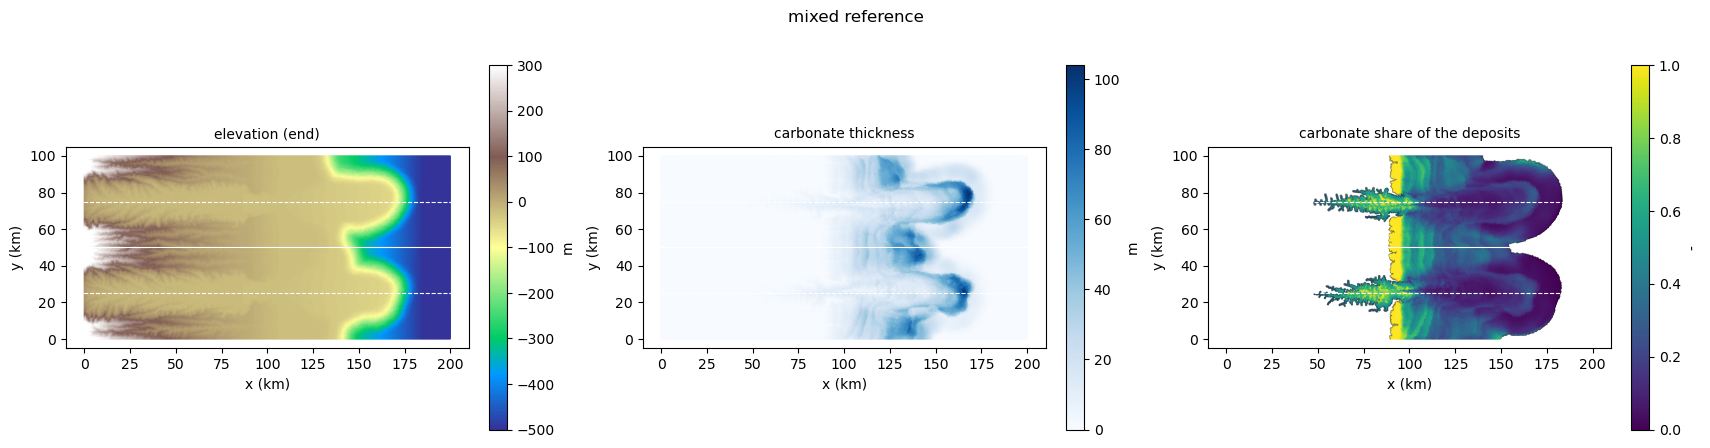

In [3]:
M.maps('sim_mixed', 'mixed reference');

Carbonate production through time, with the shoreline. The factories
follow the sea level (almost nothing during the fall at 260 kyr, a wide belt
during the rise at 500 kyr: the reciprocal sedimentation of mixed systems),
and in every period the turbid corridors in front of the river mouths stay
empty.

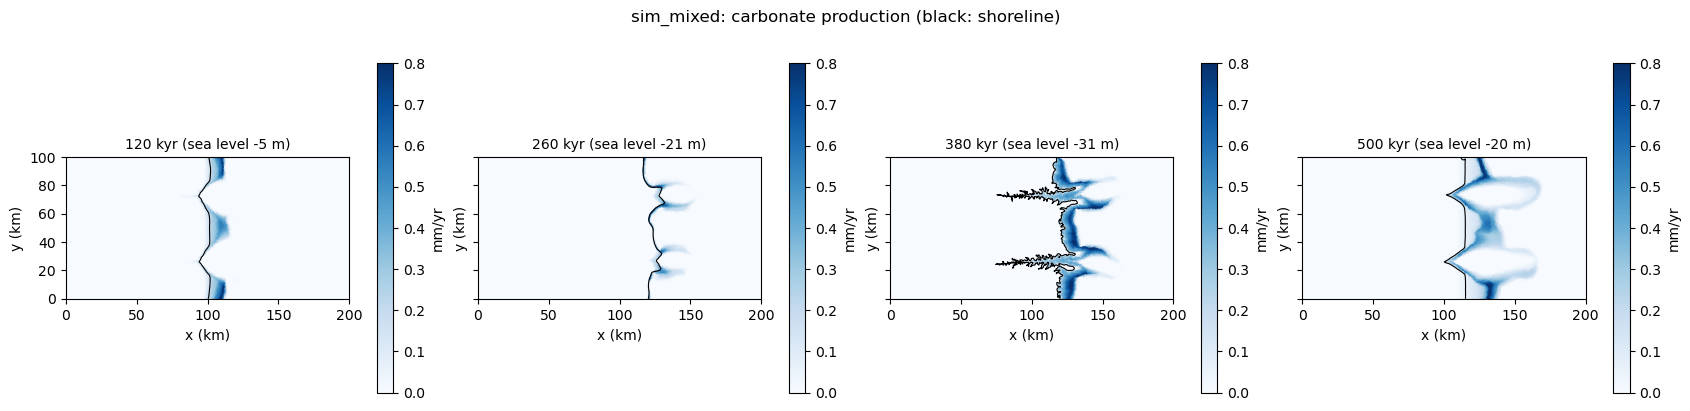

In [4]:
M.production('sim_mixed');

Sections across a delta (y = 25 km) and across the coast between the deltas
(y = 50 km), with the same section through the siliciclastic reference. The
falling stage builds clastic clinoforms (sand yellow, mud grey); carbonate
sand (light blue), carbonate mud (dark blue) and reef framework (pink) cap
them where the water is clear.

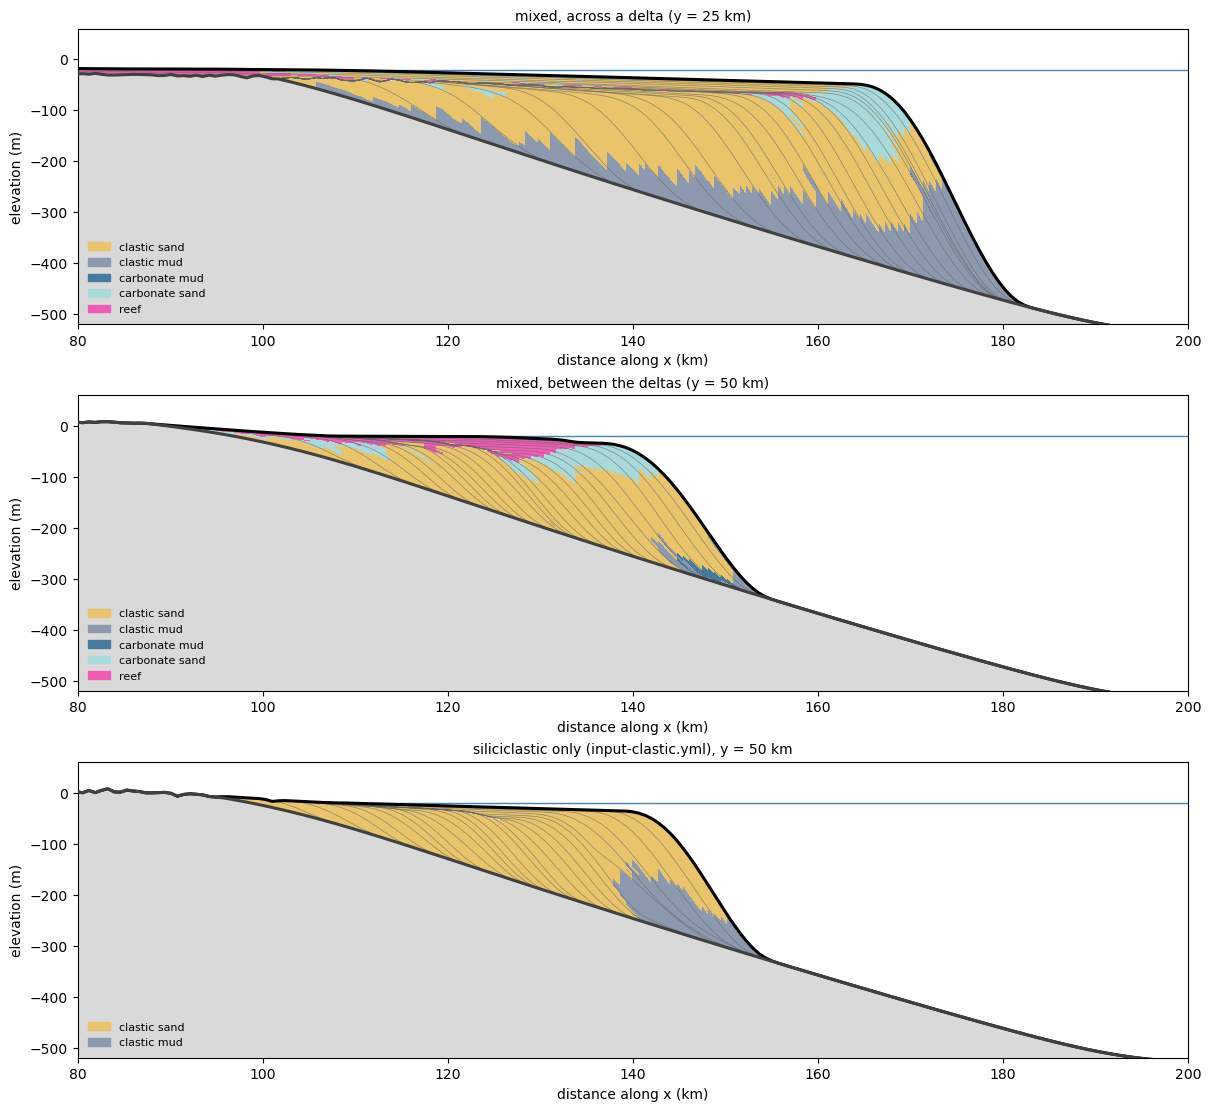

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(12, 11), constrained_layout=True)
M.section('sim_mixed', 25, ax=ax[0], title='mixed, across a delta (y = 25 km)')
M.section('sim_mixed', 50, ax=ax[1], title='mixed, between the deltas (y = 50 km)')
M.section('sim_clastic', 50, ax=ax[2], title='siliciclastic only (input-clastic.yml), y = 50 km');

## The river controls (`input-nocontrol.yml`, `input-sedrate.yml`)

| run | carbonate produced | production over the deltas / between |
|---|---|---|
| no control | 613 km3 | 1.01 |
| `sedrate` only | 474 km3 | 0.98 |
| `sedrate` + `turbidity` (mixed) | 214 km3 | 0.59 |

Without a control the factories grow on the delta fronts as well. The
`sedrate` control (production stops where 0.3 mm/yr of river sediment
accumulates) removes a fifth of the production but cannot tell the deltas
from the coast between them: on this margin the river load crosses the
shallow carbonate belt without settling and builds the clinoforms below it,
so the factories on the delta platforms see no deposition. The `turbidity`
control sees the mud in transit and stops production in the corridors.

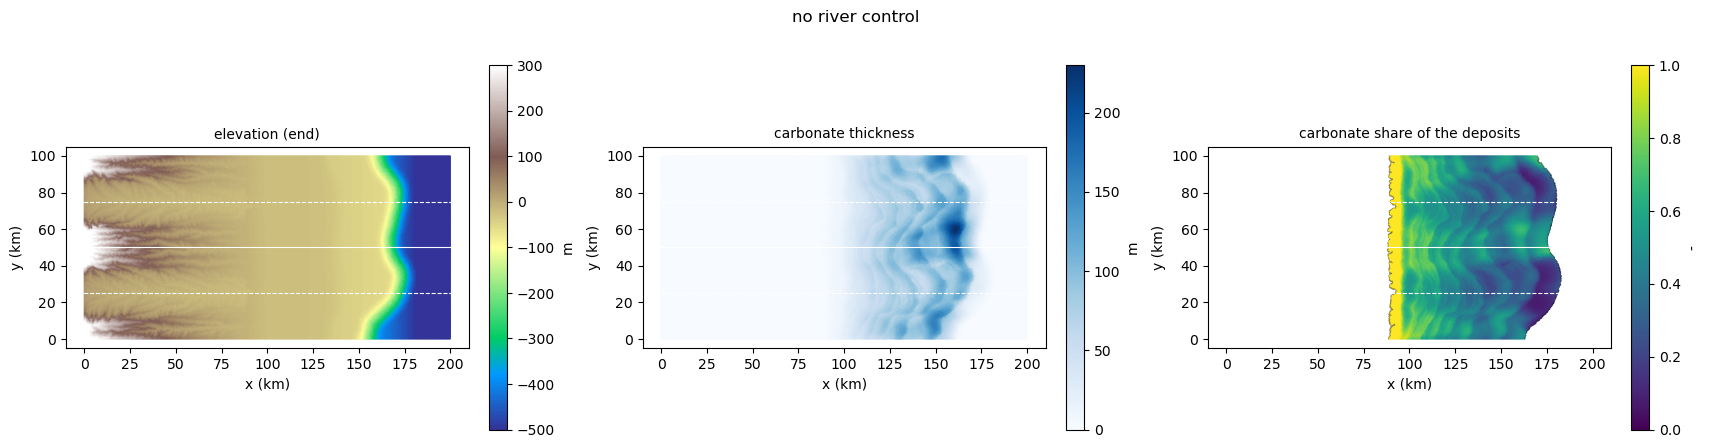

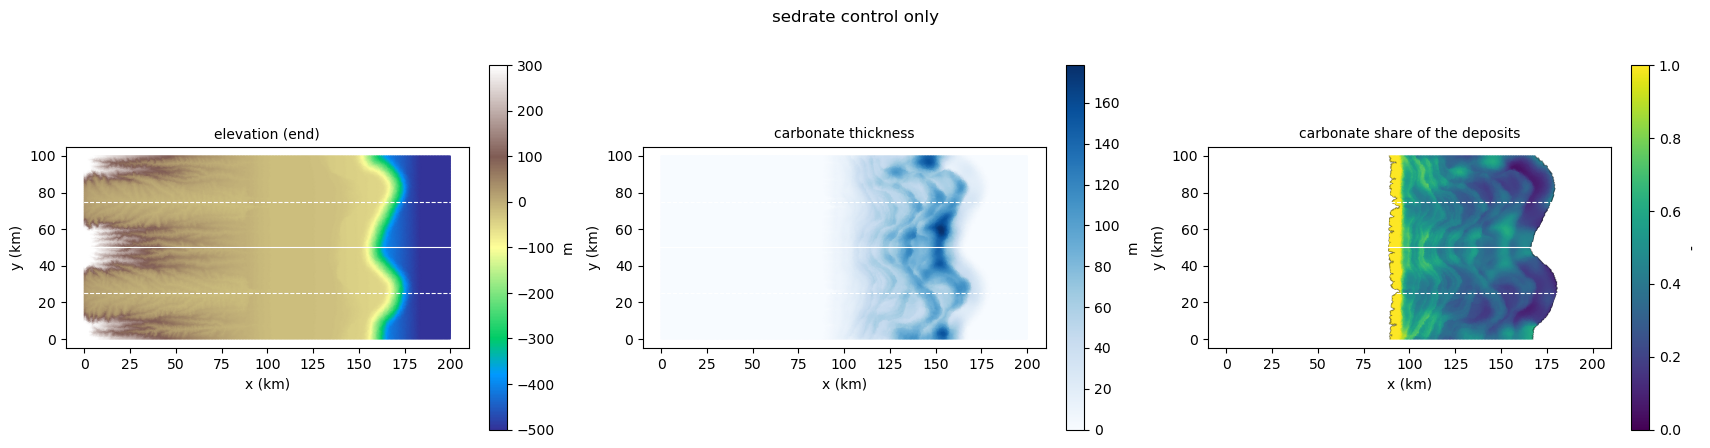

In [6]:
M.maps('sim_nocontrol', 'no river control')
M.maps('sim_sedrate', 'sedrate control only');

## Waves (`input-wavecontrol.yml`, `input-waves.yml`)

Waves from the open ocean (east) and reef builders needing wave energy: the
reef moves to the exposed fronts of the delta lobes, and the broad shallow
water between them loses the wave energy, so the euphotic factory works at
20 % there (187 km3 of carbonate against 214 without waves). With the
turbidity control already keeping the factories off the corridors, the
waves redistribute the carbonate more than they change the margin. Coastal
erosion (`input-waves.yml`) abrades the shallow water and moves the eroded
reef as carbonate sand (202 km3 produced).

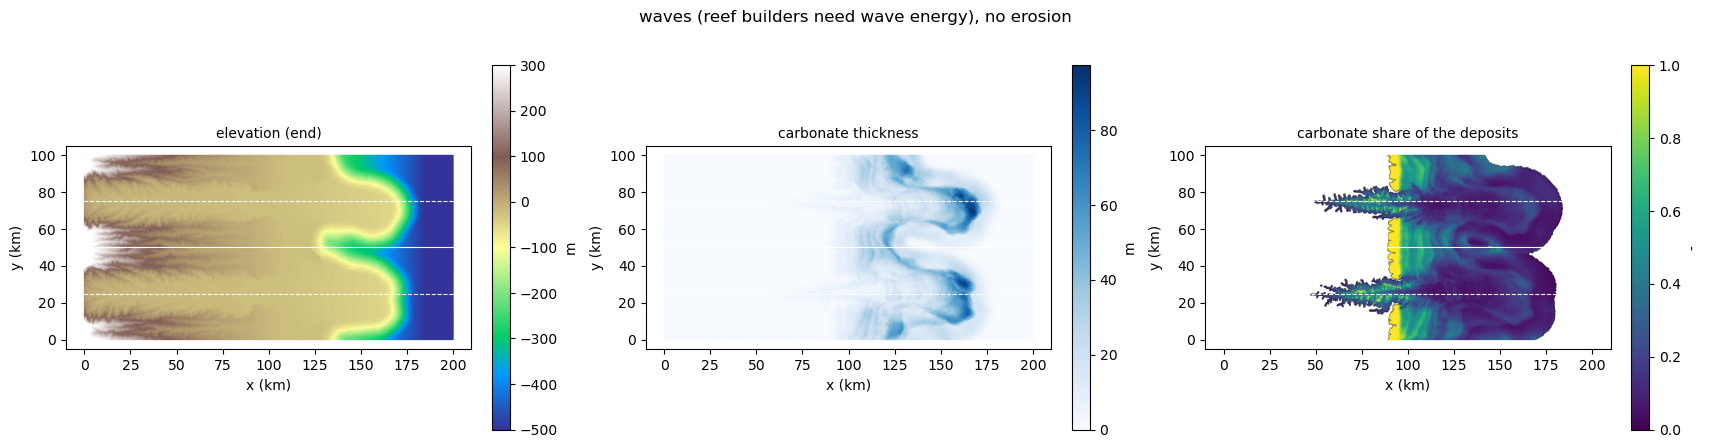

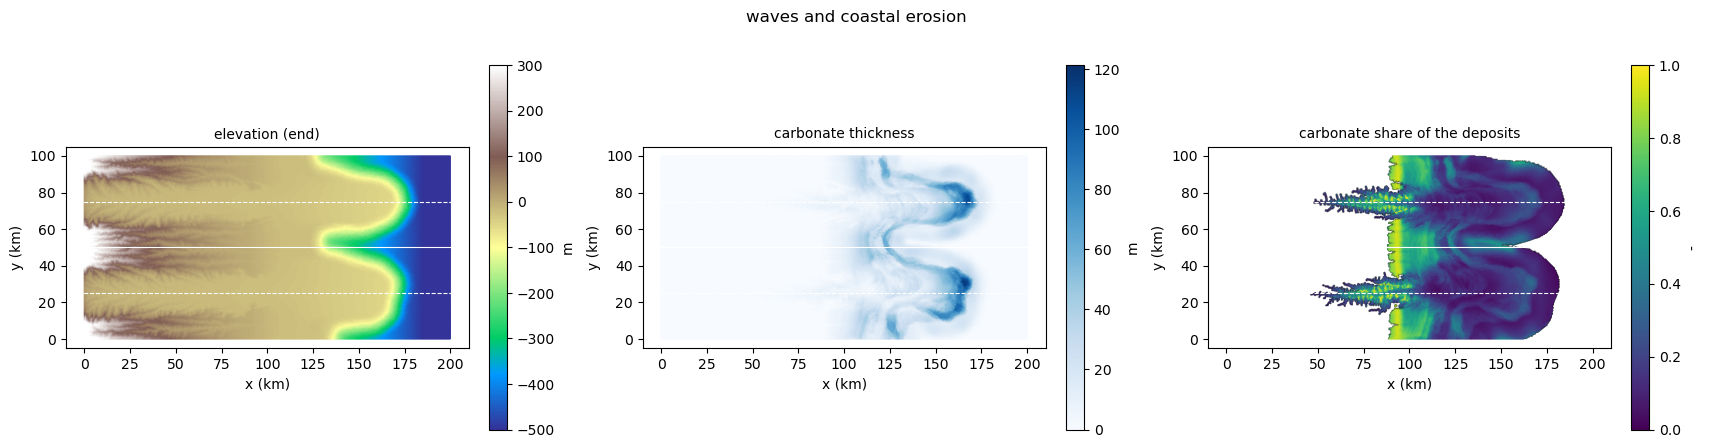

In [7]:
M.maps('sim_wavecontrol', 'waves (reef builders need wave energy), no erosion')
M.maps('sim_waves', 'waves and coastal erosion');

## Gravity currents (`input-gravity.yml`)

30 % of the river load reaching the sea runs down the slope as gravity
currents (the set-up of the `gravity_currents` example). They lay a sheet of
river sand and mud on the basin floor (32 m on average beyond 175 km,
against 7 m without). They also take that load off the shelf: less mud
crosses the shallow water, the plume is weaker, and the factories produce
more (287 km3 against 214).

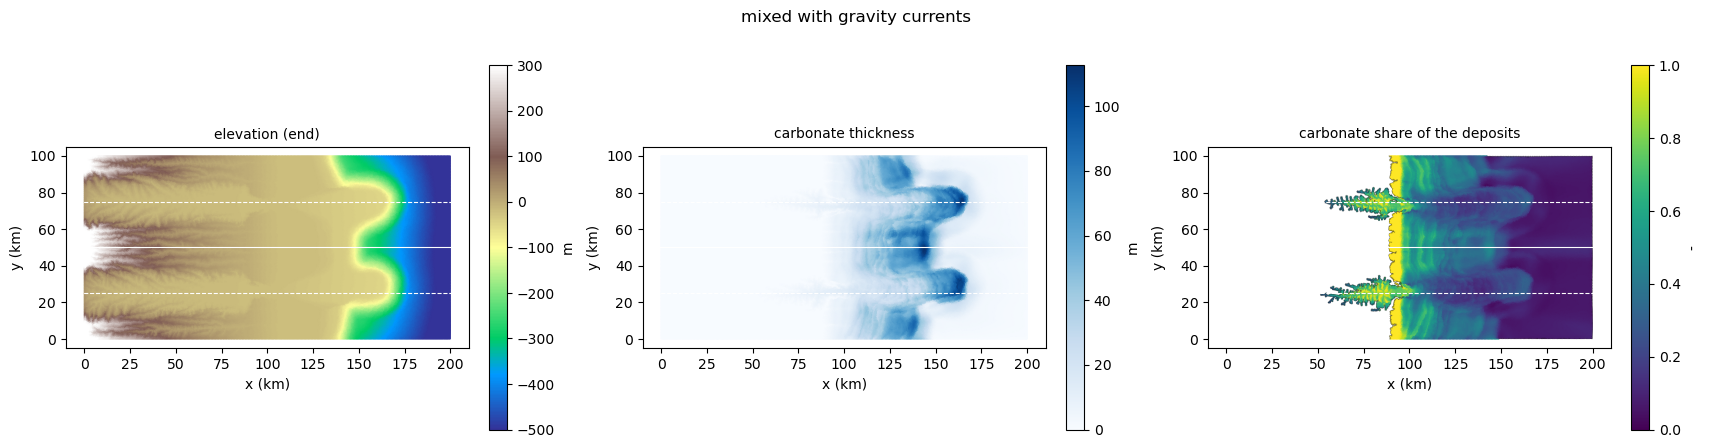

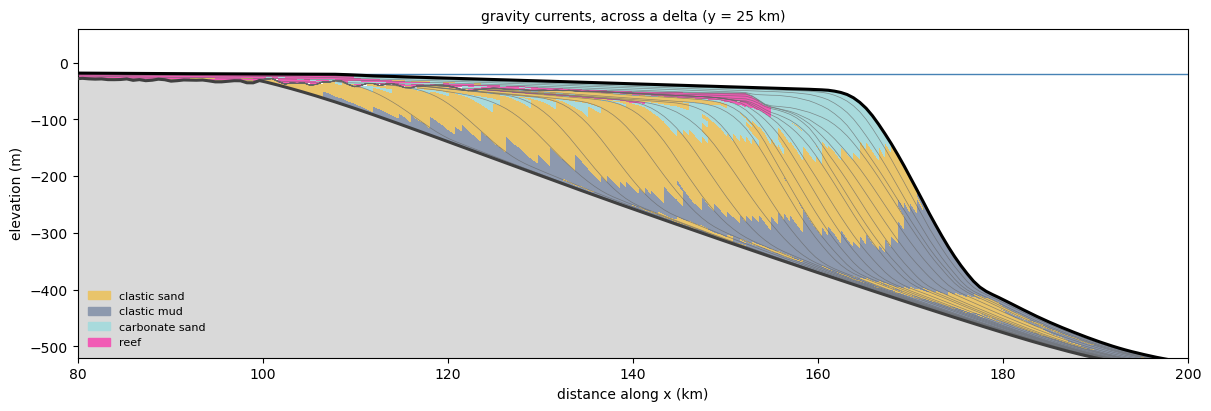

In [8]:
M.maps('sim_gravity', 'mixed with gravity currents')
M.section('sim_gravity', 25, title='gravity currents, across a delta (y = 25 km)');

## Carbonate budgets

Carbonate produced over the run, as reef framework and as loose sediment.

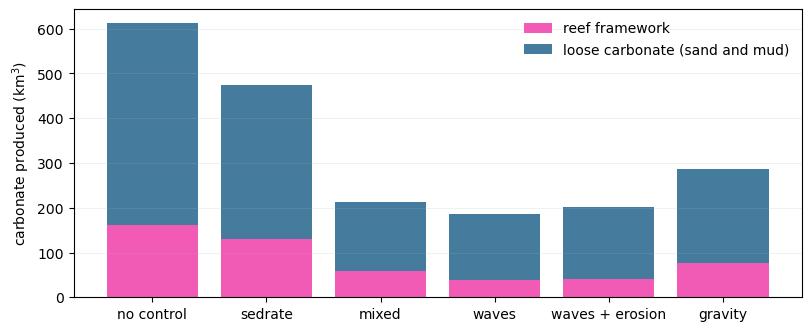

In [9]:
M.budget(['nocontrol', 'sedrate', 'mixed', 'wavecontrol', 'waves', 'gravity'],
         ['no control', 'sedrate', 'mixed', 'waves', 'waves + erosion', 'gravity']);